Завантаження

In [1]:
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("results/figures", exist_ok=True)

def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"не знайшов {name}: перевір, що змагання додано через Add Input"
    return hits[0]

tr = pd.read_csv(find("train_transaction.csv"))
idn = pd.read_csv(find("train_identity.csv"))
print("transaction:", tr.shape, "| identity:", idn.shape)

for c in tr.select_dtypes("float64").columns:   # менше пам'яті
    tr[c] = tr[c].astype("float32")

df = tr.merge(idn, on="TransactionID", how="left")
df["has_identity"] = df["TransactionID"].isin(idn["TransactionID"])
df["day"] = (df["TransactionDT"] // 86400).astype(int)
df["week"] = df["day"] // 7
del tr

transaction: (590540, 394) | identity: (144233, 41)


Розмір, фрод, час

In [2]:
print("рядків:", len(df), "| колонок:", df.shape[1])
print("унікальних TransactionID:", df.TransactionID.nunique())
print(f"фрод: {df.isFraud.sum()} ({df.isFraud.mean():.2%})")
print(f"є identity: {df.has_identity.mean():.1%} | "
      f"фрод з identity: {df[df.has_identity].isFraud.mean():.2%} | "
      f"без: {df[~df.has_identity].isFraud.mean():.2%}")
span = (df.TransactionDT.max() - df.TransactionDT.min()) / 86400
print(f"TransactionDT: {df.TransactionDT.min()} .. {df.TransactionDT.max()} (≈ {span:.0f} днів)")

рядків: 590540 | колонок: 437
унікальних TransactionID: 590540
фрод: 20663 (3.50%)
є identity: 24.4% | фрод з identity: 7.85% | без: 2.09%
TransactionDT: 86400 .. 15811131 (≈ 182 днів)


Фрод у часі

,n,fraud,rate_%
week,,,
0,23810,668,2.81
1,27803,727,2.61
2,34470,879,2.55
3,37251,690,1.85
4,24041,919,3.82
5,21868,838,3.83
6,20392,787,3.86
7,20025,825,4.12
8,20246,922,4.55


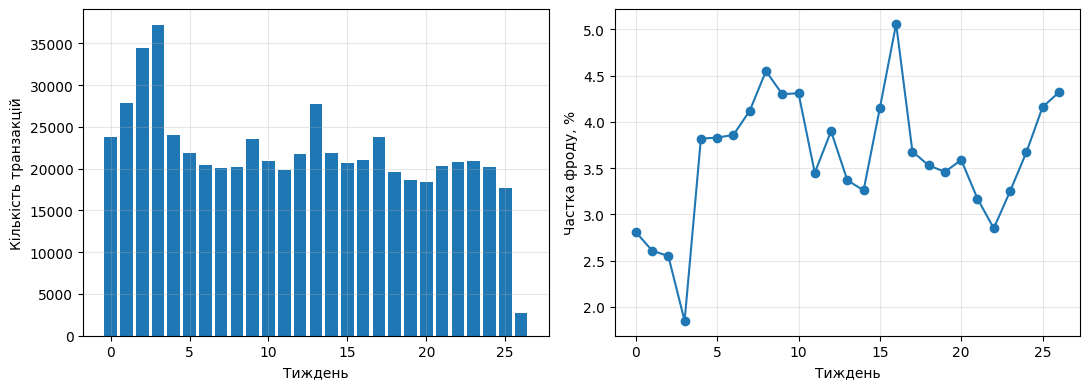

In [3]:
wk = df.groupby("week").agg(n=("isFraud", "size"), fraud=("isFraud", "sum"))
wk["rate_%"] = (wk.fraud / wk.n * 100).round(2)
display(wk)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(wk.index, wk.n)
ax[0].set_xlabel("Тиждень"); ax[0].set_ylabel("Кількість транзакцій")
ax[1].plot(wk.index, wk["rate_%"], marker="o")
ax[1].set_xlabel("Тиждень"); ax[1].set_ylabel("Частка фроду, %")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figures/ieee_cis_weekly.png", dpi=200)
plt.show()
wk.to_csv("results/ieee_cis_weekly.csv")

Аналіз пропусків

In [4]:
def group(c):
    for p, name in [(r"V\d+", "V"), (r"C\d+", "C"), (r"D\d+", "D"),
                    (r"M\d+", "M"), (r"id_\d+", "id")]:
        if re.fullmatch(p, c): return name
    if c.startswith("card"): return "card"
    if c.startswith(("addr", "dist")): return "addr/dist"
    if "emaildomain" in c: return "email"
    return "інше"

miss = df.isna().mean()
print("колонок із >50% пропусків:", (miss > 0.5).sum(), "з", len(miss))
display(miss.groupby(miss.index.map(group)).agg(["count", "mean"]).round(3))

колонок із >50% пропусків: 214 з 437


,count,mean
C,14,0.000
D,15,0.582
M,9,0.499
V,339,0.430
addr/dist,4,0.439
card,6,0.005
email,2,0.464
id,38,0.848
інше,10,0.156


З чого будуватимемо граф (кардинальність і хаби)

In [5]:
ents = ["card1","card2","card3","card4","card5","card6","addr1","addr2",
        "P_emaildomain","R_emaildomain","DeviceType","DeviceInfo","id_30","id_31","id_33"]
rows = []
for c in ents:
    s = df[c].dropna()
    vc = s.value_counts()
    rows.append({
        "колонка": c,
        "пропуски %": round(df[c].isna().mean() * 100, 1),
        "унікальних": len(vc),
        "медіана транзакцій на значення": vc.median(),
        "p99": vc.quantile(0.99),
        "максимум": vc.iloc[0],
        "топ-1 значення": str(vc.index[0]),
        "частка топ-1, %": round(vc.iloc[0] / len(s) * 100, 1),
    })
ent_stats = pd.DataFrame(rows)
display(ent_stats)
ent_stats.to_csv("results/ieee_cis_entity_stats.csv", index=False)

,колонка,пропуски %,унікальних,медіана транзакцій на значення,p99,максимум,топ-1 значення,"частка топ-1, %"
0,card1,0.0,13553,4.0,786.44,14932,7919,2.5
1,card2,1.5,500,176.0,18249.89,48935,321.0,8.4
2,card3,0.3,114,10.0,49225.25,521287,150.0,88.5
3,card4,0.3,4,98772.5,378900.50,384767,visa,65.3
4,card5,0.7,119,13.0,77125.86,296546,226.0,50.6
5,card6,0.3,4,74508.0,431209.44,439938,debit,74.7
6,addr1,11.1,332,3.0,35659.27,46335,299.0,8.8
7,addr2,11.1,74,3.5,142781.19,520481,87.0,99.2
8,P_emaildomain,16.0,59,305.0,154450.82,228355,gmail.com,46.0
9,R_emaildomain,76.8,60,113.5,39660.58,57147,gmail.com,41.6


Де фроду більше

In [6]:
for c in ["ProductCD", "card4", "card6", "DeviceType", "P_emaildomain"]:
    t = (df.groupby(c, dropna=False).isFraud.agg(["size", "mean"])
           .sort_values("size", ascending=False).head(8))
    t["mean"] = (t["mean"] * 100).round(2)
    print(c)
    display(t.rename(columns={"size": "транзакцій", "mean": "фрод %"}))

ProductCD


,транзакцій,фрод %
ProductCD,,
W,439670,2.04
C,68519,11.69
R,37699,3.78
H,33024,4.77
S,11628,5.90


card4


,транзакцій,фрод %
card4,,
visa,384767,3.48
mastercard,189217,3.43
american express,8328,2.87
discover,6651,7.73
NaN,1577,2.60


card6


,транзакцій,фрод %
card6,,
debit,439938,2.43
credit,148986,6.68
NaN,1571,2.48
debit or credit,30,0.00
charge card,15,0.00


DeviceType


,транзакцій,фрод %
DeviceType,,
NaN,449730,2.10
desktop,85165,6.52
mobile,55645,10.17


P_emaildomain


,транзакцій,фрод %
P_emaildomain,,
gmail.com,228355,4.35
yahoo.com,100934,2.28
NaN,94456,2.95
hotmail.com,45250,5.30
anonymous.com,36998,2.32
aol.com,28289,2.18
comcast.net,7888,3.12
icloud.com,6267,3.14


Чи несуть спільні ключі сигнал (як гомофілія в YelpChi)

In [7]:
def homophily(cols):
    sub = df.loc[df[cols].notna().all(axis=1), cols + ["isFraud"]]
    g = sub.groupby(cols)["isFraud"]
    n = g.transform("size"); f = g.transform("sum"); y = sub["isFraud"]
    ok = n > 1
    frac = (f - y)[ok] / (n - 1)[ok]       # частка фроду серед інших у групі
    yy = y[ok]
    return {
        "ключ": "+".join(cols),
        "охоплення %": round(ok.sum() / len(df) * 100, 1),
        "середній розмір групи": round(n[ok].mean(), 1),
        "P(фрод-сусід | вузол фрод), %": round(frac[yy == 1].mean() * 100, 1),
        "P(фрод-сусід | вузол чесний), %": round(frac[yy == 0].mean() * 100, 1),
    }

keys = [["card1"], ["addr1"], ["P_emaildomain"], ["DeviceInfo"],
        ["card1", "addr1"], ["card1", "addr1", "P_emaildomain"]]
hom = pd.DataFrame([homophily(k) for k in keys])
display(hom)
hom.to_csv("results/ieee_cis_key_homophily.csv", index=False)

,ключ,охоплення %,середній розмір групи,"P(фрод-сусід | вузол фрод), %","P(фрод-сусід | вузол чесний), %"
0,card1,99.4,2543.6,13.9,3.1
1,addr1,88.9,22492.3,3.1,2.4
2,P_emaildomain,84.0,134568.8,4.3,3.6
3,DeviceInfo,20.0,24443.3,21.5,6.2
4,card1+addr1,86.4,569.4,22.6,1.9
5,card1+addr1+P_emaildomain,67.1,156.3,38.2,1.5


Розбиття даних

In [8]:
TRAIN_W, VAL_W, TEST_W = (0, 17), (18, 21), (22, 26)

def in_weeks(w, r):
    return (w >= r[0]) & (w <= r[1])

m_tr = in_weeks(df.week, TRAIN_W).values
m_va = in_weeks(df.week, VAL_W).values
m_te = in_weeks(df.week, TEST_W).values
assert (m_tr | m_va | m_te).all() and not (m_tr & m_va).any() and not (m_va & m_te).any()

for name, m in [("train", m_tr), ("val", m_va), ("test", m_te)]:
    print(f"{name}: {m.sum()} транзакцій, фрод {df.isFraud[m].sum()} "
          f"({df.isFraud[m].mean():.2%}), дні {df.day[m].min()}-{df.day[m].max()}")

train: 431125 транзакцій, фрод 15150 (3.51%), дні 1-125
val: 77090 транзакцій, фрод 2645 (3.43%), дні 126-153
test: 82325 транзакцій, фрод 2868 (3.48%), дні 154-182


Ознаки

In [9]:
drop = ["TransactionID", "isFraud", "TransactionDT", "day", "week"]
X = df.drop(columns=drop).copy()

# сирий час моделі не даємо: на часовому розбитті вона не вміє його екстраполювати.
# натомість циклічні ознаки (відносно невідомої точки відліку, це наближення)
X["hour"] = (df.TransactionDT // 3600) % 24
X["weekday"] = (df.TransactionDT // 86400) % 7
X["has_identity"] = X["has_identity"].astype("int8")

# текстові колонки -> числові коди (мітки при цьому не використовуються)
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
for c in cat_cols:
    codes, _ = pd.factorize(X[c])
    X[c] = np.where(codes == -1, np.nan, codes).astype("float32")

y = df.isFraud.values
print("текстових колонок:", len(cat_cols), "| ознак:", X.shape[1])

текстових колонок: 31 | ознак: 434


Метрики й навчання

In [10]:
from sklearn.metrics import average_precision_score, roc_auc_score
from xgboost import XGBClassifier
import time

def metrics(y_true, p):
    k = int(y_true.sum())
    order = np.argsort(-p)
    top_k = order[:k]
    top_1 = order[: max(1, int(0.01 * len(y_true)))]
    return {
        "pr_auc": average_precision_score(y_true, p),
        "roc_auc": roc_auc_score(y_true, p),
        "recall@k": y_true[top_k].sum() / k,        # k = кількість фроду в тесті
        "precision@1%": y_true[top_1].mean(),       # точність серед 1% найризикованіших
        "base_rate": y_true.mean(),
    }

Xtr, ytr = X[m_tr], y[m_tr]
Xva, yva = X[m_va], y[m_va]
Xte, yte = X[m_te], y[m_te]
spw = (ytr == 0).sum() / (ytr == 1).sum()

def run_xgb(seed):
    m = XGBClassifier(
        n_estimators=1000, learning_rate=0.1, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
        tree_method="hist", eval_metric="aucpr", early_stopping_rounds=50,
        random_state=seed, n_jobs=-1)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    r = metrics(yte, m.predict_proba(Xte)[:, 1])
    r.update(seed=seed, best_iter=m.best_iteration, val_aucpr=m.best_score)
    return r

t0 = time.time()
r0 = run_xgb(0)
print(r0)
print("секунд:", round(time.time() - t0))

{'pr_auc': np.float64(0.5111258841093174), 'roc_auc': np.float64(0.8907456199083779), 'recall@k': np.float64(0.4909344490934449), 'precision@1%': np.float64(0.8833535844471446), 'base_rate': np.float64(0.03483753416337686), 'seed': 0, 'best_iter': 446, 'val_aucpr': 0.5424247827633609}
секунд: 524


In [11]:
pd.DataFrame([r0]).to_csv("results/ieee_cis_xgb_seed0_cpu.csv", index=False)

In [12]:
miss.groupby(miss.index.map(group)).agg(["count", "mean"]).round(3).to_csv("results/ieee_cis_missing_by_group.csv")
pd.DataFrame([r0]).to_csv("results/ieee_cis_xgb_seed0_cpu.csv", index=False)

In [1]:
import os, glob, time
import numpy as np, pandas as pd
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score
from xgboost import XGBClassifier

os.makedirs("results/figures", exist_ok=True)

def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"не знайшов {name}: перевір Add Input"
    return hits[0]

tr = pd.read_csv(find("train_transaction.csv"))
idn = pd.read_csv(find("train_identity.csv"))
for c in tr.select_dtypes("float64").columns:
    tr[c] = tr[c].astype("float32")
df = tr.merge(idn, on="TransactionID", how="left")
df["has_identity"] = df["TransactionID"].isin(idn["TransactionID"])
df["day"] = (df["TransactionDT"] // 86400).astype(int)
df["week"] = df["day"] // 7
del tr

# часове розбиття (configs/ieee_cis_split.yaml)
TRAIN_W, VAL_W, TEST_W = (0, 17), (18, 21), (22, 26)
inw = lambda r: ((df.week >= r[0]) & (df.week <= r[1])).values
m_tr, m_va, m_te = inw(TRAIN_W), inw(VAL_W), inw(TEST_W)
assert (m_tr | m_va | m_te).all() and not (m_tr & m_va).any() and not (m_va & m_te).any()
for n, m in [("train", m_tr), ("val", m_va), ("test", m_te)]:
    print(f"{n}: {m.sum()} транзакцій, фрод {df.isFraud[m].sum()} ({df.isFraud[m].mean():.2%})")

# ознаки
X = df.drop(columns=["TransactionID", "isFraud", "TransactionDT", "day", "week"]).copy()
X["hour"] = (df.TransactionDT // 3600) % 24
X["weekday"] = (df.TransactionDT // 86400) % 7
X["has_identity"] = X["has_identity"].astype("int8")
for c in X.select_dtypes(include=["object", "category"]).columns:
    codes, _ = pd.factorize(X[c])
    X[c] = np.where(codes == -1, np.nan, codes).astype("float32")
y = df.isFraud.values
Xtr, ytr, Xva, yva, Xte, yte = X[m_tr], y[m_tr], X[m_va], y[m_va], X[m_te], y[m_te]
spw = (ytr == 0).sum() / (ytr == 1).sum()

def metrics(y_true, p):
    k = int(y_true.sum()); order = np.argsort(-p)
    top1 = order[: max(1, int(0.01 * len(y_true)))]
    return {"pr_auc": average_precision_score(y_true, p),
            "roc_auc": roc_auc_score(y_true, p),
            "recall@k": y_true[order[:k]].sum() / k,
            "precision@1%": y_true[top1].mean(),
            "base_rate": y_true.mean()}

# GPU-налаштування залежно від версії XGBoost
major = int(xgb.__version__.split(".")[0])
DEV = dict(tree_method="hist", device="cuda") if major >= 2 else dict(tree_method="gpu_hist")
print("xgboost", xgb.__version__, DEV)

def run_xgb(seed):
    m = XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=6,
                      subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                      eval_metric="aucpr", early_stopping_rounds=50,
                      random_state=seed, **DEV)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    r = metrics(yte, m.predict_proba(Xte)[:, 1])
    r.update(seed=seed, best_iter=m.best_iteration, val_aucpr=m.best_score)
    return r

train: 431125 транзакцій, фрод 15150 (3.51%)
val: 77090 транзакцій, фрод 2645 (3.43%)
test: 82325 транзакцій, фрод 2868 (3.48%)
xgboost 3.4.1 {'tree_method': 'hist', 'device': 'cuda'}


In [2]:
t0 = time.time()
r0 = run_xgb(0)
print(r0, "| секунд:", round(time.time() - t0))

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [11:24:38] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


{'pr_auc': np.float64(0.49983392399461496), 'roc_auc': np.float64(0.8802892656043761), 'recall@k': np.float64(0.48779637377963736), 'precision@1%': np.float64(0.8833535844471446), 'base_rate': np.float64(0.03483753416337686), 'seed': 0, 'best_iter': 801, 'val_aucpr': 0.5573231228128178} | секунд: 43


In [3]:
rows = [r0] + [run_xgb(s) for s in range(1, 5)]
res = pd.DataFrame(rows)
res.to_csv("results/ieee_cis_xgb_baseline.csv", index=False)
res[["pr_auc", "roc_auc", "recall@k", "precision@1%", "best_iter"]].agg(["mean", "std"]).round(3)

,pr_auc,roc_auc,recall@k,precision@1%,best_iter
mean,0.505,0.886,0.487,0.876,659.20
std,0.003,0.005,0.006,0.007,158.49
